In [1]:
from fastebm import FastEBM
import numpy as np
import pandas as pd
import random
import time
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from typing import Tuple

# FastEBM on Synthetic Data

Here we are going to run FastEBM on synthetic data where we know the ground truth ordering. We can control the number of subjects and the noise level.

## Synthetic Data Generation

In [2]:
def give_me_data(N = 5, patients = 1000, controls = 1000, noise_scale = 0.2):
    """
    Generate synthetic data for event-based modeling.

    Biomarker names are randomly permuted to create a ground-truth ordering.
    Gaussian noise is added to the simulated data.

    Parameters
    ----------
    N : int, default=5
        Number of biomarkers (features).
    patients : int, default=1000
        Number of patient subjects.
    controls : int, default=1000
        Number of control subjects.
    noise_scale : float, default=0.2
        Standard deviation of the noise added to the data.

    Returns
    -------
    data : pandas.DataFrame
        DataFrame containing the simulated dataset.
    ordering : list of str
        Ground-truth ordering of biomarkers.
    """
    # This code is based on: https://github.com/ucl-pond/kde_ebm/blob/master/examples/kde_ebm_walkthrough.ipynb
    try:
        dp = np.linspace(0, N*4 + 50, int(patients))
        def sigmoid(t,a=1,b=-10):
            return 1/(1 + np.exp(-a*(t-b)))
        
        gradients = np.array([1 for i in range(N)])
        onsets    = np.array([4*(i+1) for i in range(0,N)])
        X = np.empty(shape=(int(patients),N))
        for a,b,k in zip(gradients,onsets,range(len(gradients))):
            x = sigmoid(t=dp,a=a,b=b)
            y = x + np.random.normal(0, noise_scale, x.size)
            X[:,k] = y
        X_controls = np.empty(shape=(int(controls),N))
        for k in range(len(gradients)):
            X_controls[:,k] = np.random.normal(0, noise_scale, (X_controls.shape[0],))
        y          = np.ones(shape=(X.shape[0],1))
        y_controls = np.zeros(shape=(X_controls.shape[0],1))
        X_patients_controls = np.concatenate((X,X_controls),axis=0)
        y_patients_controls = np.concatenate((y,y_controls),axis=0)
        X = X_patients_controls
        y = y_patients_controls.flatten().astype(int)
        y = y + 1
        print("--------------------------------------")
        print(f"Successfully generated synthetic dataset.")
        print(f"{patients} patients (stage == 2) and {controls} controls (stage == 1) ({patients + controls} total subjects).")
        print(f"Noise level was set to {noise_scale}.")
        print("--------------------------------------")
        GT_sequence = np.argsort(onsets)
        random.shuffle(GT_sequence)             # randomly shuffling the biomarker names
        ground_truth_order = [f'biomarker_{i}' for i in GT_sequence]   # creating names for features
        X_stage = np.append(X, np.array([y]).transpose(), axis = 1)
        X_stage = pd.DataFrame(X_stage, columns=ground_truth_order + ['stage']) # last column is the stage column. controls == 1, patients == 2
        return X_stage, ground_truth_order
    except Exception as e:
        print("ERROR: Failed to generate the sysnthetic dataset:")
        raise    

In [3]:
# generating synthetic data
num_patients = 1000     # number of patients
num_controls = 1000     # number of controls
num_features = 100      # number of features
level_of_noise = 0.8    # level of noise in the data
X_fastebm, ground_truth_order = give_me_data(N = num_features, patients = num_patients, controls = num_controls, noise_scale = level_of_noise)
print(X_fastebm.stage.value_counts())   # Sanity check
X_fastebm.head()

--------------------------------------
Successfully generated synthetic dataset.
1000 patients (stage == 2) and 1000 controls (stage == 1) (2000 total subjects).
Noise level was set to 0.8.
--------------------------------------
stage
2.0    1000
1.0    1000
Name: count, dtype: int64


,biomarker_76,biomarker_46,biomarker_10,biomarker_84,biomarker_73,biomarker_77,biomarker_32,biomarker_1,biomarker_56,biomarker_70,...,biomarker_61,biomarker_0,biomarker_79,biomarker_44,biomarker_6,biomarker_38,biomarker_57,biomarker_43,biomarker_93,stage
0,0.372169,-0.678012,-0.986115,0.275719,-0.025744,0.873510,-0.576541,-0.354416,-1.767944,-1.279171,...,-0.384271,-0.945810,0.092497,1.326860,-0.009779,0.468288,0.409665,-0.262092,0.276647,2.0
1,0.227590,-1.156311,0.579922,1.523026,0.545333,-1.245721,1.178115,-0.415019,-0.008615,1.739952,...,0.232740,-0.549739,0.440052,0.836856,-0.476425,-1.403359,-0.373809,-0.757809,0.140849,2.0
2,0.677763,0.949059,-0.156824,-0.086211,0.548620,0.879676,-1.111698,-0.722234,0.414118,-0.272940,...,-1.180208,0.681134,0.822376,0.373784,0.969457,0.624549,0.286624,-0.003789,-0.889945,2.0
3,-0.133173,0.156587,-0.634231,0.715655,-0.954570,0.413839,-0.331267,0.556221,1.287839,-0.564821,...,0.373343,0.743407,-0.210175,-0.969908,0.981535,2.588462,0.731712,-0.872870,-0.039593,2.0
4,-0.293094,-0.758758,-0.779295,-0.473185,0.186255,0.807162,1.398241,1.081242,-0.416575,0.638984,...,0.073509,1.019286,-0.320367,-0.690451,-0.224854,-0.031552,0.436789,-1.235515,-0.775884,2.0


## Data Preprocessing

In the latest version of FastEBM, we z-score the data relative to a control group. Here, we're using all of controls from our synthetic data.

In [4]:
## z-scoring data relative to the control population
data_control = X_fastebm.loc[X_fastebm.stage == 1].iloc[:, :-1]

# compute the mean and standard deviation of the control population
mean_control = np.mean(data_control,axis=0)
std_control = np.std(data_control,axis=0)
z_fastebm = (X_fastebm.iloc[:,:-1]-mean_control)/std_control
z_fastebm['stage'] = X_fastebm['stage']

In [5]:
z_fastebm

,biomarker_76,biomarker_46,biomarker_10,biomarker_84,biomarker_73,biomarker_77,biomarker_32,biomarker_1,biomarker_56,biomarker_70,...,biomarker_61,biomarker_0,biomarker_79,biomarker_44,biomarker_6,biomarker_38,biomarker_57,biomarker_43,biomarker_93,stage
0,0.435720,-0.811959,-1.240536,0.380668,-0.002952,1.076700,-0.719069,-0.432649,-2.130907,-1.584876,...,-0.477274,-1.127895,0.103696,1.622046,0.022586,0.590909,0.545276,-0.311345,0.412642,2.0
1,0.257421,-1.411431,0.713893,1.946177,0.708210,-1.574108,1.462424,-0.507248,-0.020813,2.155620,...,0.305891,-0.636021,0.526682,1.021340,-0.562897,-1.733311,-0.458054,-0.916507,0.243416,2.0
2,0.812586,1.227313,-0.205573,-0.073593,0.712305,1.084412,-1.384407,-0.885412,0.486202,-0.338222,...,-1.487548,0.892580,0.991982,0.453650,1.251196,0.784954,0.387707,0.003987,-1.041124,2.0
3,-0.187481,0.234077,-0.801381,0.932837,-1.159621,0.501727,-0.414129,0.688291,1.534121,-0.699843,...,0.484356,0.969915,-0.264665,-1.193608,1.266350,3.223750,0.957694,-1.056971,0.018555,2.0
4,-0.384700,-0.913162,-0.982422,-0.559289,0.261050,0.993709,1.736098,1.334562,-0.510110,0.791593,...,0.103781,1.312526,-0.398772,-0.851016,-0.247260,-0.029795,0.580012,-1.499682,-0.898985,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-0.298700,-0.719038,1.806735,0.025356,-0.663499,-0.506569,0.491327,1.533532,-1.402525,1.038947,...,0.485018,-1.017052,-0.602420,-0.857722,2.344611,-0.653069,0.492359,0.285830,1.217953,1.0
1996,0.897294,0.377062,-0.068940,-0.770255,0.546745,-0.884674,0.759893,0.896350,-1.435156,0.581744,...,-1.068551,0.998107,0.398420,1.223176,1.847791,-1.548951,-0.158209,-0.773347,-0.207471,1.0
1997,-1.202434,-1.052696,0.840947,-0.385064,-1.589370,0.625021,1.101073,0.166231,-1.278139,0.129917,...,1.036538,-0.600838,-0.684224,0.878494,-0.243128,-1.003552,0.825364,-0.981066,1.586572,1.0
1998,-0.514154,-0.525188,-1.468976,-0.182206,3.009558,0.031752,0.734785,1.573433,0.412571,1.478173,...,-0.252597,-0.728514,1.244546,-0.658488,-0.405533,-1.050474,-0.300713,0.341293,0.195728,1.0


## FastEBM

In [6]:
## Create a FastEBM object
start_time = time.time()
my_fastebm = FastEBM(data = z_fastebm, ordering_method = 'median_template', zFastEBM = True, n_neighbors = 1, anamoly_model = 'l2', return_dps= True, seed = None)

## Calculate the subject ordering
X_fastebm_ordered = my_fastebm.get_subject_ordering()

## Calculate the biomarker ordering
fastebm_ordered_biomarkers, event_index_dict = my_fastebm.get_event_ordering()
finished = time.time() - start_time
print(f"FastEBM finished after {finished}")

FastEBM finished after 0.7110669612884521


Accuracy calculation (Kendall's Tau):

For this we need to create a rank list

for example if in the ground truth ordering we have ['biomarker_97', 'biomarker_24']

Then biomarker_97 has rank 0 and biomarker_24 has rank 1 and so on. 


In [7]:
ground_truth_rank = [i for i in range(len(ground_truth_order))]     # for kendall's tau the input has to be int
fastebm_rank = []
# for fastebm we go over the ground truth order of biomarkers and 
# get their index (or ranking) from the ordered list
for bm in ground_truth_order:
    fastebm_rank.append(fastebm_ordered_biomarkers.index(bm))
print(f"Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is {stats.kendalltau(fastebm_rank, ground_truth_rank).statistic}")

Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is 0.9321212121212122


# FastEBM on "Real" Data

Here, we use a simulated data, but with features similar to a real dataset.

In [8]:
# This simulated data is taken from https://github.com/ucl-pond/pySuStaIn/blob/master/notebooks/SimulatedData.csv
real_data = pd.read_csv('../data/simulated_data.csv')
real_data.head()

,subject_id,Age,Headsize,Biomarker1,Biomarker2,Biomarker3,Biomarker4,Biomarker5,diagnosis
0,1,63.501953,0.920706,132.511729,180.698267,120.119201,159.200991,190.197486,2
1,2,61.240101,0.952784,154.500427,194.299318,179.148420,173.515194,237.807726,2
2,3,52.108876,1.061493,140.878957,170.449488,160.945261,163.988839,207.271331,2
3,4,65.989165,0.871652,146.361556,175.111234,164.769410,114.437784,184.657121,2
4,5,65.071640,1.147264,167.254806,203.470448,232.783278,212.857075,245.588402,2


## Preprocessing data

In [9]:
# Getting the features we want to order
biomarkers = ["Biomarker1",	"Biomarker2", "Biomarker3",	"Biomarker4", "Biomarker5"]

## alternative way to get feature names (if you have a lot of features):
# biomarkers = list((set(real_data.columns)).difference(set(['Age', 'Headsize', 'diagnosis', 'subject_id'])))

In [10]:
# Parts of the code below is taken from https://github.com/ucl-pond/pySuStaIn/blob/master/notebooks/SuStaInWorkshop.ipynb

z_fastebm = pd.DataFrame(real_data,copy=True)   # creating a deep of copy of data so that we don't overwrite things

# for each biomarker
for biomarker in biomarkers:
    mod = smf.ols('%s ~ Age + Headsize'%biomarker,  # fit a model finding the effect of age and headsize on biomarker
                  data=real_data[real_data.diagnosis==1] # fit this model *only* to individuals in the control group
                 ).fit() # fit model    
    #print(mod.summary())
    
    # get the "predicted" values for all subjects based on the control model parameters
    predicted = mod.predict(real_data[['Age','Headsize',biomarker]]) 
    
    # calculate our zscore: observed - predicted / SD of the control group residuals
    w_score = (real_data.loc[:,biomarker] - predicted) / mod.resid.std()
    
    #print(np.mean(w_score[data.Diagnosis==0]))
    #print(np.std(w_score[data.Diagnosis==0]))
    
    # save zscore back into our new (copied) dataframe
    z_fastebm.loc[:,biomarker] = w_score

In [14]:
start_time = time.time()
## Create a FastEBM object
my_fastebm = FastEBM(data = z_fastebm[biomarkers + ['diagnosis']], ordering_method = 'median_template', zFastEBM = True, n_neighbors = 3, anamoly_model = 'l2', seed = None)

## Calculate the subject ordering
X_fastebm_ordered = my_fastebm.get_subject_ordering()   # maybe add an option to return DPS

## Calculate the biomarker ranking
fastebm_ordered_biomarkers, event_index_dict = my_fastebm.get_event_ordering()    # maybe add an option to return abnormality index
finished = time.time() - start_time
print(f"FastEBM is Done! (total time: {finished})")

print(f"Feature ranking: {fastebm_ordered_biomarkers}")
print("--------------------------------------")

FastEBM is Done! (total time: 0.03610086441040039)
Feature ranking: ['Biomarker1', 'Biomarker3', 'Biomarker4', 'Biomarker5', 'Biomarker2']
--------------------------------------


## Post-processing Data

In [15]:
# You can use the index of the ordered datafraame to re-order the original data and perform any data
fastebm_ordered_indices = X_fastebm_ordered.index
z_fastebm.iloc[fastebm_ordered_indices]

,subject_id,Age,Headsize,Biomarker1,Biomarker2,Biomarker3,Biomarker4,Biomarker5,diagnosis
5,6,67.098566,1.087909,-0.162680,-0.028358,-0.026596,0.755776,-0.301466,1
48,49,57.915898,1.134305,0.148798,-0.028109,-1.455693,1.949199,-0.482928,1
327,328,68.068357,1.036630,0.554742,-0.245032,0.679061,-0.469736,0.262555,2
457,458,59.260545,1.011170,-0.804484,1.309455,0.175937,0.943114,-1.780423,1
356,357,62.298187,1.007321,0.588663,0.612584,-0.152738,-0.519258,0.314222,2
...,...,...,...,...,...,...,...,...,...
160,161,61.745126,0.792514,5.327958,4.636054,5.126139,5.524332,6.475228,2
173,174,63.252789,1.091635,4.230479,3.903281,5.535703,5.924101,6.586085,2
391,392,65.422302,1.060433,5.076307,5.171748,6.370613,5.746694,5.230733,2
21,22,73.302801,1.094979,5.632416,5.167916,6.300853,6.922146,5.467371,2


# Detecting and Working with Correlated Features

If a number of features are correlated with each other, this can negatively affect the performance of FastEBM. To help solve this problem, FastEBM provides two functions to automatically detect and merge correlated features using PCA. 

In [16]:
from fastebm import detect_correlated_features, merge_correlated_features

In [17]:
# generating synthetic data
num_patients = 1000     # number of patients
num_controls = 1000     # number of controls
num_features = 100      # number of features
level_of_noise = 0.8    # level of noise in the data
X_fastebm, ground_truth_order = give_me_data(N = num_features, patients = num_patients, controls = num_controls, noise_scale = level_of_noise)
print(X_fastebm.stage.value_counts())   # Sanity check
X_fastebm.head()

--------------------------------------
Successfully generated synthetic dataset.
1000 patients (stage == 2) and 1000 controls (stage == 1) (2000 total subjects).
Noise level was set to 0.8.
--------------------------------------
stage
2.0    1000
1.0    1000
Name: count, dtype: int64


,biomarker_15,biomarker_60,biomarker_3,biomarker_63,biomarker_18,biomarker_16,biomarker_4,biomarker_23,biomarker_97,biomarker_76,...,biomarker_41,biomarker_83,biomarker_48,biomarker_57,biomarker_21,biomarker_2,biomarker_59,biomarker_67,biomarker_92,stage
0,-0.061952,-0.123266,-0.244453,-1.239670,-1.542061,-0.337792,0.045643,-0.383786,1.934982,0.255684,...,0.087073,-1.278848,-0.007455,0.348796,1.115285,0.575516,-0.151881,-0.940844,-0.462461,2.0
1,0.761558,1.213855,0.992539,0.336194,0.395715,-0.038393,0.267675,-1.060669,-0.757515,-1.349188,...,1.200389,-0.034974,-0.769151,-0.953693,-1.286388,0.384212,-2.264737,0.657942,-2.178867,2.0
2,0.449433,1.135228,0.112560,0.254782,-0.508851,-0.057475,-0.574384,-0.364076,0.733946,-0.999406,...,-0.356279,0.720601,0.978536,0.847927,1.654649,-1.457648,0.301449,-0.668199,1.200912,2.0
3,1.068133,-1.541026,0.682438,-0.866781,-1.979238,-0.535784,0.091108,0.164732,0.608019,0.312409,...,-0.311218,-0.421001,-0.352895,-0.490486,0.949639,0.214826,-1.459832,-1.112872,-0.794354,2.0
4,-0.046778,-1.241472,-0.660697,0.587609,0.074933,-0.732615,0.108442,-0.280593,1.423119,0.864305,...,0.821415,0.092842,0.741938,0.636061,0.215237,0.333149,-0.047417,-0.559798,0.371764,2.0


In [18]:
# function to generate some correlated features
def create_correlated_features(df, feature_name, N, noise_level=0.1, seed=None):
    if seed is not None:
        np.random.seed(seed)

    for i in range(1, N + 1):
        noise = np.random.normal(loc=0.0, scale=noise_level, size=len(df))
        new_feature = df[feature_name] + noise
        df[f'{feature_name}_corr_{i}'] = new_feature

    return df


df = X_fastebm.copy()
df = create_correlated_features(df, 'biomarker_27', N=10, noise_level=0.2, seed=42)
df = create_correlated_features(df, 'biomarker_51', N=15, noise_level=0.2, seed=42)

df['fastebm_stage'] = df['stage']
df = df.drop(['stage'], axis = 1)
df.head()


,biomarker_15,biomarker_60,biomarker_3,biomarker_63,biomarker_18,biomarker_16,biomarker_4,biomarker_23,biomarker_97,biomarker_76,...,biomarker_51_corr_7,biomarker_51_corr_8,biomarker_51_corr_9,biomarker_51_corr_10,biomarker_51_corr_11,biomarker_51_corr_12,biomarker_51_corr_13,biomarker_51_corr_14,biomarker_51_corr_15,fastebm_stage
0,-0.061952,-0.123266,-0.244453,-1.239670,-1.542061,-0.337792,0.045643,-0.383786,1.934982,0.255684,...,0.979251,0.699440,0.920150,0.808656,0.813946,0.472762,0.610014,0.716020,1.097407,2.0
1,0.761558,1.213855,0.992539,0.336194,0.395715,-0.038393,0.267675,-1.060669,-0.757515,-1.349188,...,-0.366079,-0.032450,0.017579,-0.146555,0.066382,-0.015641,-0.133043,-0.226787,0.145827,2.0
2,0.449433,1.135228,0.112560,0.254782,-0.508851,-0.057475,-0.574384,-0.364076,0.733946,-0.999406,...,-0.266339,0.246305,-0.383245,-0.062509,-0.388084,0.029974,0.084301,-0.224721,-0.065920,2.0
3,1.068133,-1.541026,0.682438,-0.866781,-1.979238,-0.535784,0.091108,0.164732,0.608019,0.312409,...,-0.924038,-0.753844,-1.008206,-1.033779,-0.799790,-0.901976,-0.542824,-0.886107,-1.095192,2.0
4,-0.046778,-1.241472,-0.660697,0.587609,0.074933,-0.732615,0.108442,-0.280593,1.423119,0.864305,...,-0.703326,-0.210377,-0.637937,-0.556596,-1.004524,-0.518690,-0.892284,-0.602741,-0.352695,2.0


In [19]:
# you need to pass your data and groups of correlated features with average correlation value is returned
best_corr_clusters = detect_correlated_features(df = df.iloc[:,:-1])

Feature Clusters:
('biomarker_27', 'biomarker_27_corr_1', 'biomarker_27_corr_10', 'biomarker_27_corr_2', 'biomarker_27_corr_3', 'biomarker_27_corr_4', 'biomarker_27_corr_5', 'biomarker_27_corr_6', 'biomarker_27_corr_7', 'biomarker_27_corr_8', 'biomarker_27_corr_9'): avg corr = 0.96
('biomarker_51', 'biomarker_51_corr_1', 'biomarker_51_corr_10', 'biomarker_51_corr_11', 'biomarker_51_corr_12', 'biomarker_51_corr_13', 'biomarker_51_corr_14', 'biomarker_51_corr_15', 'biomarker_51_corr_2', 'biomarker_51_corr_3', 'biomarker_51_corr_4', 'biomarker_51_corr_5', 'biomarker_51_corr_6', 'biomarker_51_corr_7', 'biomarker_51_corr_8', 'biomarker_51_corr_9'): avg corr = 0.96


In [20]:
# If we're happy with the feature clusters, we can group them together using PCA
df_decorr = merge_correlated_features(df = df.iloc[:,:-1], correlated_clusters = best_corr_clusters)
# We're bringing back the stage value in the decorrelated dataframe
df_decorr['stage'] = df['fastebm_stage'].values

Once the data is decorrelated, we do the same preprocessing as before.

In [21]:
## z-scoring data relative to the control population
data_control = df_decorr.loc[df_decorr.stage == 1].iloc[:, :-1]

# compute the mean and standard deviation of the control population
mean_control = np.mean(data_control,axis=0)
std_control = np.std(data_control,axis=0)
z_fastebm = (df_decorr.iloc[:,:-1]-mean_control)/std_control
z_fastebm['stage'] = df_decorr['stage']

In [22]:
## Create a FastEBM object
start_time = time.time()
my_fastebm = FastEBM(data = df_decorr, ordering_method = 'median_template', zFastEBM = True, n_neighbors = 3, anamoly_model = 'l2', return_dps = True, seed = None)

## Calculate the subject ordering
X_fastebm_ordered = my_fastebm.get_subject_ordering()

## Calculate the biomarker ordering
fastebm_ordered_biomarkers, event_order_dict = my_fastebm.get_event_ordering()
finished = time.time() - start_time
print(f"FastEBM finished after {finished}")

FastEBM finished after 1.044389009475708


After FastEBM is done, we want to bring back the correlated features and order them. So we can use this helper function from FastEBM to order the data with the OG features. 

In [23]:
# This is a helper function that performs changepoint detection and orders features
from fastebm import changepoint_detect_and_order

In [24]:
fastebm_ordered_indices = X_fastebm_ordered.index   # get the ordered indices
# order the original dataframe with the correlated features and order the features
ordered_corr_features = changepoint_detect_and_order(df.iloc[fastebm_ordered_indices])

# Plotting Biomarker Curves

Once the subjects are ordered. We can plot the curves against the pseudotime axis. We can plot the z-scored data, or the original data. Below are the z-scored data. 

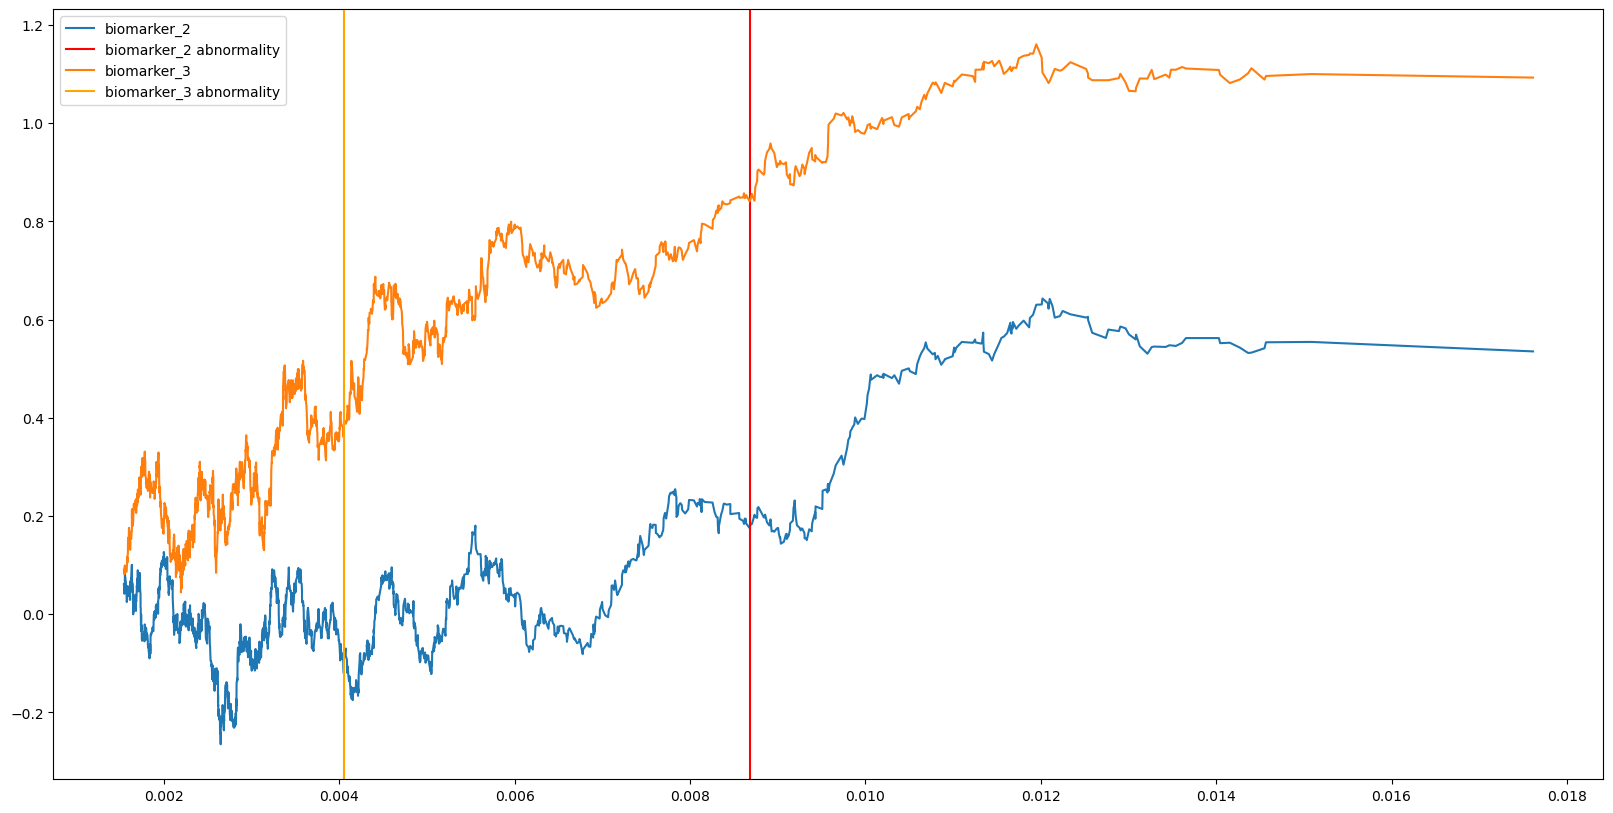

In [26]:
plt.figure(figsize=(20, 10))
plt.plot(X_fastebm_ordered['DPS'].values, X_fastebm_ordered['biomarker_2'].rolling(100).mean(), label = 'biomarker_2')
plt.axvline(x = X_fastebm_ordered.iloc[event_order_dict['biomarker_2']]['DPS'], color = 'red', label = 'biomarker_2 abnormality')

plt.plot(X_fastebm_ordered['DPS'].values, X_fastebm_ordered['biomarker_3'].rolling(100).mean(), label = 'biomarker_3')
plt.axvline(x = X_fastebm_ordered.iloc[event_order_dict['biomarker_3']]['DPS'], color = 'orange', label = 'biomarker_3 abnormality')
plt.legend()

# Plotting Positional Heatmap

We can plot and view the biomarker orderings using a heatmap.

In [27]:
# You can customize this function
def create_positional_heatmap(
    data_dict: dict, 
    figsize: Tuple[int, int] = (10, 8), 
    dpi: int = 300, 
    annot: bool = True, 
    cmap: str = "viridis",
    font_size: int = 8  # Added to control font size
):
    """
    Creates a high-quality positional heatmap using Matplotlib/Seaborn.
    Calculates dynamic height to ensure all y-axis labels are shown.
    """
    
    # 1. Convert the dictionary to a pandas DataFrame
    try:
        df = pd.DataFrame.from_dict(data_dict, orient='index', columns=['original_position'])
        df = df.reset_index().rename(columns={'index': 'feature_name'})
    except Exception as e:
        print(f"Error converting dictionary to DataFrame: {e}")
        return None

    if df.empty:
        print("Input dictionary is empty.")
        return None

    df['rank_position'] = df['original_position'].rank(method='dense').astype(int)
    df = df.sort_values(by='original_position')

    try:
        df_pivot = df.pivot(index='feature_name', columns='rank_position', values='original_position')
    except Exception as e:
        print(f"Error pivoting data: {e}")
        return None

    feature_order = df['feature_name'].tolist()
    rank_order = sorted(df['rank_position'].unique())
    df_pivot = df_pivot.reindex(index=feature_order, columns=rank_order)
    n_features = len(df_pivot.index)
    fig_width = figsize[0]
    dynamic_height = (n_features * 0.3) + 2
    fig_height = max(figsize[1], dynamic_height)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=dpi)


    sns.heatmap(
        df_pivot,
        # annot=annot,
        fmt=".0f",            
        cmap=cmap,            
        cbar_kws={'label': 'Original Index Value',
        'shrink': 0.6}, 
        linewidths=.5,       
        linecolor='lightgray',
        ax=ax
    )

    ax.set_title('Feature Positional Diagram', fontsize=16)
    ax.set_xlabel('Position (Rank)', fontsize=12)
    ax.set_ylabel('Feature Name', fontsize=12)
    
    ax.tick_params(axis='x', rotation=0)
    
    ax.tick_params(axis='y', rotation=0, labelsize=font_size) 
    
    return fig, ax

(<Figure size 3000x9600 with 2 Axes>,
 <Axes: title={'center': 'Feature Positional Diagram'}, xlabel='Position (Rank)', ylabel='Feature Name'>)

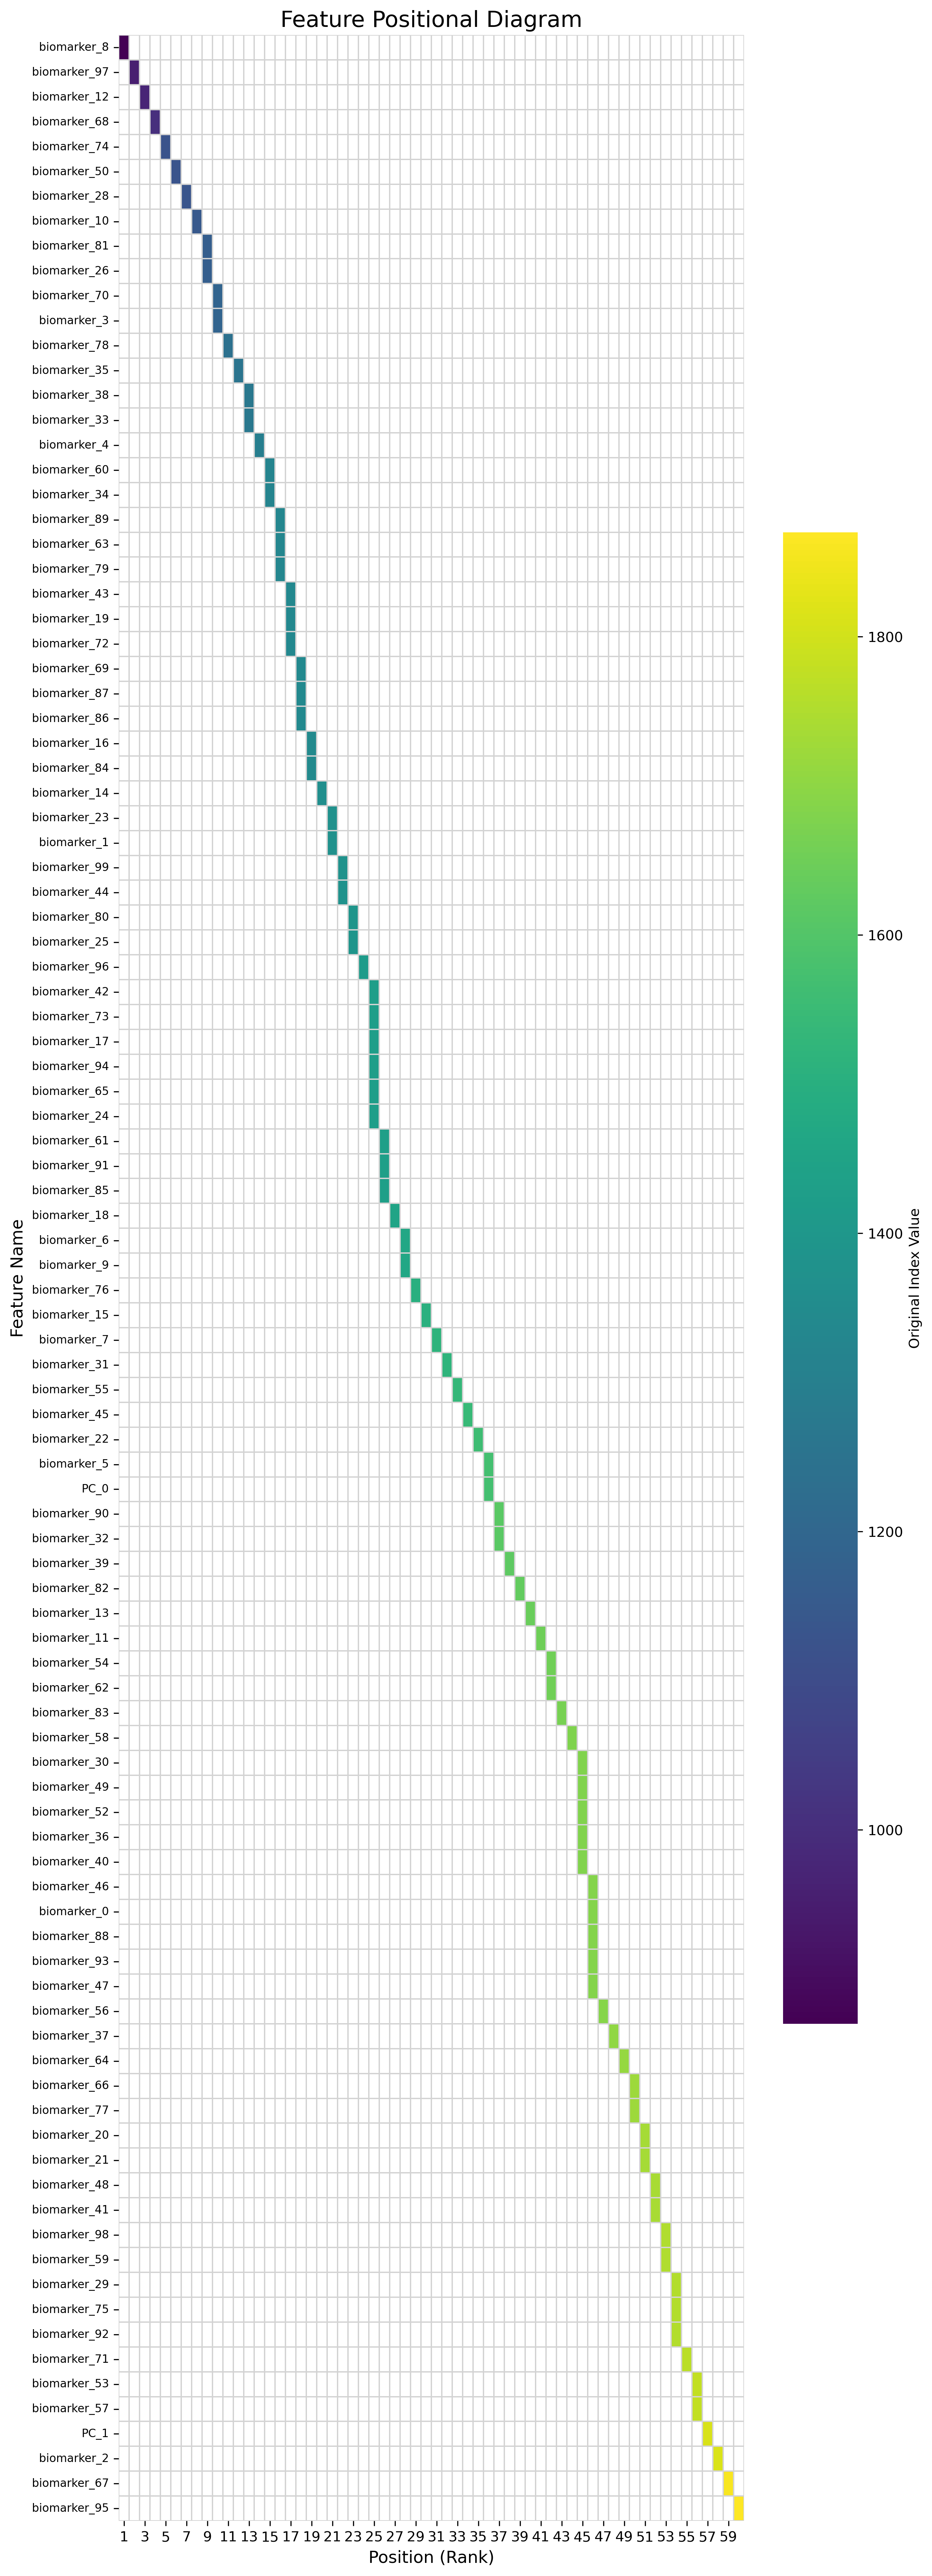

In [28]:
# The input is the 'biomarker' --> 'abnormality index' dictionary
create_positional_heatmap(event_order_dict)

# FastEBM with Stage Info

## Simulating New Data

In [29]:
## Let's simulate some new data
# generating synthetic data
num_patients = 1000     # number of patients
num_controls = 1000     # number of controls
num_features = 100      # number of features
level_of_noise = 0.4    # level of noise in the data
X_fastebm, ground_truth_order = give_me_data(N = num_features, patients = num_patients, controls = num_controls, noise_scale = level_of_noise)
print(X_fastebm.stage.value_counts())   # Sanity check
X_fastebm.head()

--------------------------------------
Successfully generated synthetic dataset.
1000 patients (stage == 2) and 1000 controls (stage == 1) (2000 total subjects).
Noise level was set to 0.4.
--------------------------------------
stage
2.0    1000
1.0    1000
Name: count, dtype: int64


,biomarker_26,biomarker_43,biomarker_4,biomarker_5,biomarker_13,biomarker_14,biomarker_87,biomarker_69,biomarker_57,biomarker_9,...,biomarker_73,biomarker_75,biomarker_10,biomarker_97,biomarker_81,biomarker_28,biomarker_2,biomarker_34,biomarker_0,stage
0,-0.611296,-0.600388,-0.971008,0.297868,0.227985,0.607347,-0.372838,0.113809,-0.152237,-0.660059,...,-0.293076,0.088359,-0.075709,-0.470217,0.529481,-0.364908,-0.209663,0.362361,-0.053133,2.0
1,-0.149688,-1.103099,0.117650,0.255924,-0.649192,0.644878,0.296099,0.044489,-0.532333,-0.501574,...,-0.670565,-0.191672,0.076270,-0.258437,0.839891,0.088930,0.083868,-0.166478,0.355509,2.0
2,0.523894,0.363515,-0.046447,-0.285390,0.139219,-0.152295,0.246083,0.632567,0.723508,0.256433,...,0.155369,0.321249,-0.333332,0.553614,-0.360914,-0.080968,0.702749,0.146470,0.324487,2.0
3,-0.510782,0.097978,-0.874747,-0.015596,0.676094,-0.328255,0.158644,-0.101610,0.008932,0.734803,...,-0.056383,0.299593,-0.057650,-0.379478,0.538974,0.312093,-0.295199,0.057506,-0.376323,2.0
4,0.041996,0.240972,0.277255,-0.221373,-0.000773,0.189859,0.214988,-0.701393,0.301658,-0.666134,...,1.101033,0.295934,-0.199379,0.751010,1.184634,0.093141,0.279880,0.098829,1.153814,2.0


## Preprocessing
Instead of z-scoring we do min-max normalization

In [30]:
stage_values = X_fastebm.stage.values
min_max_fastebm = (X_fastebm.iloc[:, :-1] - X_fastebm.iloc[:, :-1].min()) / (X_fastebm.iloc[:, :-1].max() - X_fastebm.iloc[:, :-1].min())
min_max_fastebm['stage'] = stage_values
min_max_fastebm.head()

,biomarker_26,biomarker_43,biomarker_4,biomarker_5,biomarker_13,biomarker_14,biomarker_87,biomarker_69,biomarker_57,biomarker_9,...,biomarker_73,biomarker_75,biomarker_10,biomarker_97,biomarker_81,biomarker_28,biomarker_2,biomarker_34,biomarker_0,stage
0,0.160611,0.159313,0.126313,0.502664,0.466788,0.499764,0.288947,0.384580,0.289481,0.165210,...,0.366713,0.418165,0.407813,0.257675,0.561637,0.295248,0.324595,0.553913,0.415523,2.0
1,0.288413,0.020638,0.420646,0.490862,0.223367,0.510529,0.461996,0.365803,0.180371,0.208559,...,0.270524,0.345062,0.452160,0.312124,0.649842,0.445560,0.402868,0.384817,0.531852,2.0
2,0.474901,0.425209,0.376280,0.338540,0.442155,0.281884,0.449057,0.525096,0.540871,0.415889,...,0.480982,0.478961,0.332638,0.520906,0.308627,0.389290,0.567898,0.484882,0.523021,2.0
3,0.188440,0.351959,0.152338,0.414458,0.591141,0.231415,0.426437,0.326229,0.335746,0.546734,...,0.427025,0.473308,0.413082,0.281004,0.564335,0.519473,0.301786,0.456436,0.323519,2.0
4,0.341483,0.391405,0.463797,0.356554,0.403306,0.380020,0.441013,0.163765,0.419775,0.163548,...,0.721950,0.472352,0.371725,0.571657,0.747802,0.446955,0.455136,0.469649,0.759109,2.0


## Running FastEBM

In [31]:
## Create a FastEBM object
start_time = time.time()

## zFastEBM is now False
my_fastebm = FastEBM(data = min_max_fastebm, ordering_method = 'median_template', zFastEBM = False, n_neighbors = 1, anamoly_model = 'l2', return_dps= True, seed = None)

## Calculate the subject ordering
X_fastebm_ordered = my_fastebm.get_subject_ordering()

## Calculate the biomarker ordering
fastebm_ordered_biomarkers, event_index_dict = my_fastebm.get_event_ordering()
finished = time.time() - start_time
print(f"FastEBM finished after {finished}")

FastEBM finished after 0.6588048934936523


In [32]:
ground_truth_rank = [i for i in range(len(ground_truth_order))]     # for kendall's tau the input has to be int
fastebm_rank = []
# for fastebm we go over the ground truth order of biomarkers and 
# get their index (or ranking) from the ordered list
for bm in ground_truth_order:
    fastebm_rank.append(fastebm_ordered_biomarkers.index(bm))
print(f"Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is {stats.kendalltau(fastebm_rank, ground_truth_rank).statistic}")

Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is 0.9886868686868688


# Kemeny-Snell First-Passage DPS Noise UQ

This section computes the Kemeny-Snell mean first-passage matrix and first-passage variance matrix from the Markov-chain fundamental matrix. The stationary-distribution-weighted first-passage variance is converted into subject-level DPS noise, then subjects are reordered repeatedly and biomarker events are re-estimated.

In [ ]:
# import importlib
from fastebm.uncertainty import first_passage_uncertainty as fastebm_uncertainty

num_patients = 1000     # number of patients
num_controls = 1000     # number of controls
num_features = 50      # number of features
level_of_noise = 0.8    # level of noise in the data
X_fastebm, ground_truth_order = give_me_data(N = num_features, patients = num_patients, controls = num_controls, noise_scale = level_of_noise)
## z-scoring data relative to the control population
data_control = X_fastebm.loc[X_fastebm.stage == 1].iloc[:, :-1]

# compute the mean and standard deviation of the control population
mean_control = np.mean(data_control,axis=0)
std_control = np.std(data_control,axis=0)
z_fastebm = (X_fastebm.iloc[:,:-1]-mean_control)/std_control
z_fastebm['stage'] = X_fastebm['stage']


first_passage_stage_col = z_fastebm.columns[-1]
first_passage_feature_cols = [feature for feature in ground_truth_order if feature in z_fastebm.columns]
first_passage_uq_source = z_fastebm.loc[:, [*first_passage_feature_cols, first_passage_stage_col]].copy()
first_passage_uq_data = first_passage_uq_source.copy()

# first_passage_n_neighbors = min(5, len(first_passage_uq_data) - 1)
first_passage_n_neighbors = 1
first_passage_support_n_neighbors = min(15, len(first_passage_uq_data) - 1)

first_passage_uq = fastebm_uncertainty(
    first_passage_uq_data,
    n_noise_samples=1000,
    ordering_method='median_template',
    n_neighbors=first_passage_n_neighbors,
    support_n_neighbors=None,
    min_segment_size=4,
    dps_noise_scale=None,
    normalize_subject_variance=True,
    seed=11,
    convergence_check_interval=25,
    convergence_min_samples=20,
    event_rank_convergence_tol=0.25,
    convergence_patience=1,
)

--------------------------------------
Successfully generated synthetic dataset.
1000 patients (stage == 2) and 1000 controls (stage == 1) (2000 total subjects).
Noise level was set to 0.8.
--------------------------------------


In [49]:
ground_truth_rank = [i for i in range(len(ground_truth_order))]     # for kendall's tau the input has to be int
fastebm_rank = []
# for fastebm we go over the ground truth order of biomarkers and 
# get their index (or ranking) from the ordered list
for bm in ground_truth_order:
    fastebm_rank.append(list(first_passage_uq.event_summary.sort_values(by ='rank_median').index).index(bm))
print(f"Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is {stats.kendalltau(fastebm_rank, ground_truth_rank).statistic}")

Kendall's Tau rank correlation between ground truth ranking and FastEBM ranking is 0.9248979591836736


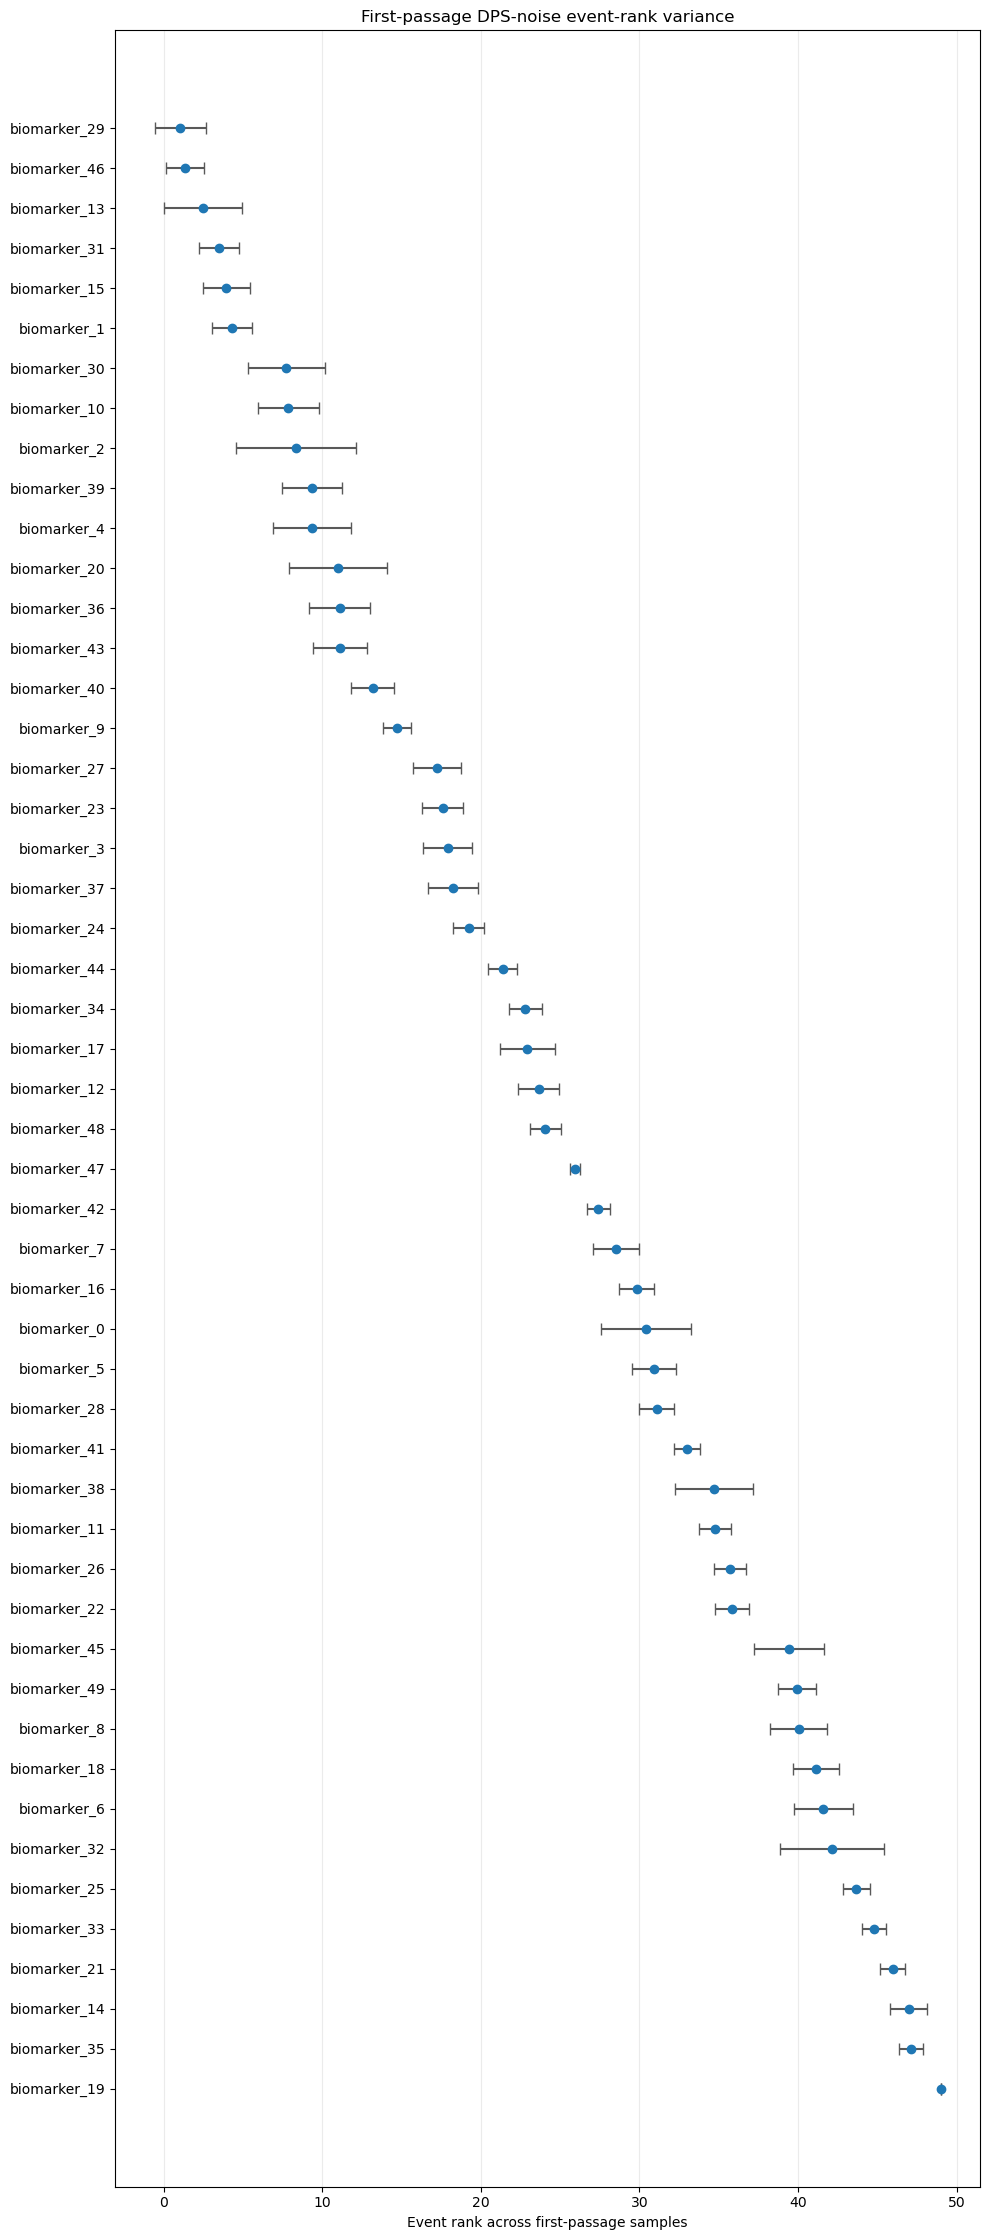

In [50]:
rank_variance_result = first_passage_uq
rank_variance_title = 'First-passage DPS-noise event-rank variance'

rank_variance_summary = rank_variance_result.event_summary.copy()
rank_variance_summary['feature_name'] = rank_variance_summary.index
rank_variance_summary = rank_variance_summary.sort_values(
    ['rank_mean', 'rank_median', 'feature_name'],
    kind='mergesort',
)

fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(rank_variance_summary))))
y_pos = np.arange(len(rank_variance_summary))
ax.errorbar(
    rank_variance_summary['rank_mean'],
    y_pos,
    xerr=rank_variance_summary['rank_std'],
    fmt='o',
    capsize=4,
    color='tab:blue',
    ecolor='0.35',
)
ax.set_yticks(y_pos)
ax.set_yticklabels(rank_variance_summary['feature_name'])
ax.invert_yaxis()
ax.set_xlabel('Event rank across first-passage samples')
ax.set_title(rank_variance_title)
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()
